### 1. Load and Preprocess the MNIST Data

In [40]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

#### 1.1 Load the MNIST Dataset

In [41]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

The MNIST dataset contains 60,000 training images and 10,000 test images of handwritten digits from 0 to 9. Each image has a size of 28 × 28 pixels.

#### 1.2 Normalize the Input Data

In [42]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

The pixel values were normalized from 0–255 to 0–1 by dividing them by 255. This helps the models train more efficiently.

#### 1.3 Flatten the images

In [43]:
# Flatten images for MLP only
X_train_MLP = X_train.reshape(X_train.shape[0], 784)
X_test_MLP = X_test.reshape(X_test.shape[0], 784)

The 28 × 28 images were flattened into 784 pixel values for the MLP because it requires one-dimensional input. The original 28 × 28 images were kept for the RNN to process row by row.

#### 1.4 One-Hot Encoder

In [44]:
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

The labels were converted into one-hot encoded vectors with 10 values, representing digits from 0 to 9. This allows the models to use categorical cross-entropy as the loss function.

### 2. MultiLayer Perceptron (MLP)

#### 2.1 Build the MLP Model

In [45]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
## Create the Model
MLP_Model = Sequential()
## Input Layer and the 1st hidden layer
MLP_Model.add(Dense(128, activation='relu', input_shape=(784,)))
## The 2nd hidden layer
MLP_Model.add(Dense(64, activation='relu'))
## Output Layer
MLP_Model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


The MLP contains two hidden layers with 128 and 64 neurons using ReLU activation. The output layer has 10 neurons with Softmax activation to classify the handwritten digits. The model has 109,386 trainable parameters.

#### 2.2 Train and Evaluate MLP Using Five Random Seeds

In [54]:
import numpy as np
import time

seeds = [42, 123, 456, 2026, 1313291]
MLP_results = []
MLP_History = []

for seed in seeds:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    # Build a fresh MLP for each seed
    MLP_Model = Sequential([
        Dense(128, activation='relu', input_shape=(784,)),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    MLP_Model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    start_time = time.time()

    history = MLP_Model.fit(
        X_train_MLP,
        y_train,
        epochs=10,
        batch_size=128,
        verbose=0
    )

    MLP_History.append(history.history)

    training_time = time.time() - start_time

    test_loss, test_accuracy = MLP_Model.evaluate(
        X_test_MLP, y_test, verbose=0
    )

    MLP_results.append({
        'Seed': seed,
        'Training Accuracy': history.history['accuracy'][-1],
        'Test Accuracy': test_accuracy,
        'Training Loss': history.history['loss'][-1],
        'Parameters': MLP_Model.count_params(),
        'Training Time': training_time
    })

    print(f"Seed {seed}: Test Accuracy = {test_accuracy * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Seed 42: Test Accuracy = 97.69%
Seed 123: Test Accuracy = 97.41%
Seed 456: Test Accuracy = 97.64%
Seed 2026: Test Accuracy = 97.29%
Seed 1313291: Test Accuracy = 97.43%


The MLP was trained five times using different random seeds to check how consistent its performance was. Each run used the same architecture, optimizer, batch size, and number of epochs. The training accuracy, test accuracy, training loss, number of parameters, and training time were recorded for comparison.

#### 2.3 Calculate MLP Mean and Standard Deviation

In [55]:
import pandas as pd

## Convert results into Dataframe
MLP_results_df = pd.DataFrame(MLP_results)

## Calculate Mean and Standard Deviation
MLP_Summary = MLP_results_df.drop(columns=['Seed']).agg(['mean', 'std'])

## Display Summary
MLP_Summary


,Training Accuracy,Test Accuracy,Training Loss,Parameters,Training Time
mean,0.994977,0.974920,0.019294,109386.0,16.91353
std,0.000513,0.001677,0.001255,0.0,0.43919


The mean and standard deviation were calculated from the five training runs. The mean represents the average performance of the MLP, while the standard deviation shows how much the results changed between different random seeds. These values will be used to compare the MLP and RNN.

### 3. Recurrent Neural Network (RNN)

#### 3.1 Build the RNN Model

In [56]:
from tensorflow.keras.layers import Input, SimpleRNN
from tensorflow.keras.models import Model

## Create the Model
RNN_Model = Sequential()

RNN_Model.add(Input(shape=(28, 28)))
## Each Image contains 28 rows,with 28 pixel values per row
RNN_Model.add(SimpleRNN(128, activation='tanh'))
## Processes the rows one after another and maintains a hidden state containing learned information.
RNN_Model.add(Dense(10, activation='softmax'))
## Uses the final hidden state to predict one of the 10 digits.

RNN_Model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        20,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,386 (83.54 KB)

 Trainable params: 21,386 (83.54 KB)

 Non-trainable params: 0 (0.00 B)

The RNN processes each MNIST image as a sequence of 28 rows, with 28 pixel values in each row. A SimpleRNN layer with 64 hidden units learns information from the sequence. The final hidden state is passed to a Dense layer with 10 neurons to classify the handwritten digit.

#### 3.2 Train and Evaluate RNN Using Five Random Seeds

In [57]:
RNN_results = []
RNN_History = []

for seed in seeds:
  tf.keras.backend.clear_session()
  tf.keras.utils.set_random_seed(seed)

## Create Fresh RNN Model for each seed
  RNN_Model = Sequential([
      Input(shape=(28, 28)),
      SimpleRNN(128, activation='tanh'),
      Dense(10, activation='softmax')
  ])
  RNN_Model.compile(
      optimizer='adam',
      loss='categorical_crossentropy',
      metrics=['accuracy']
  )
  start_time = time.time()
  history = RNN_Model.fit(
      X_train,
      y_train,
      epochs=10,
      batch_size=128,
      verbose=0
  )
  RNN_History.append(history.history)
  training_time = time.time() - start_time
  test_loss, test_accuracy = RNN_Model.evaluate(
      X_test, y_test, verbose=0
  )
  RNN_results.append({
      'Seed': seed,
      'Training Accuracy': history.history['accuracy'][-1],
      'Test Accuracy': test_accuracy,
      'Training Loss': history.history['loss'][-1],
      'Parameters': RNN_Model.count_params(),
      'Training Time': training_time
  })
  print(f"Seed {seed}: Test Accuracy = {test_accuracy * 100:.2f}%")

Seed 42: Test Accuracy = 97.04%
Seed 123: Test Accuracy = 97.42%
Seed 456: Test Accuracy = 97.21%
Seed 2026: Test Accuracy = 96.94%
Seed 1313291: Test Accuracy = 97.17%


The RNN was trained five times using the same random seeds as the MLP. Each run used the same architecture, optimizer, batch size, and number of epochs. The training accuracy, test accuracy, training loss, number of parameters, and training time were recorded to compare the two models.

#### 3.3 Calculate the RNN Mean and Standard Deviation

In [58]:
RNN_results_df = pd.DataFrame(RNN_results)
RNN_Summary = RNN_results_df.drop(columns=['Seed']).agg(['mean', 'std'])
RNN_Summary

,Training Accuracy,Test Accuracy,Training Loss,Parameters,Training Time
mean,0.974860,0.971560,0.084152,21386.0,29.106415
std,0.001825,0.001823,0.004542,0.0,1.185430


The mean and standard deviation were calculated from the five RNN training runs. The mean shows the average performance, while the standard deviation shows how much the results varied between random seeds. These results will be compared with the MLP results.

### 4. MLP vs RNN


#### 4.1 MLP vs RNN Performance Comparison

In [59]:
# Format results as mean ± standard deviation
def format_result(summary, metric, percentage=False):
    mean = summary.loc['mean', metric]
    std = summary.loc['std', metric]

    if percentage:
        mean *= 100
        std *= 100

    return f"{mean:.4f} ± {std:.4f}" if metric == 'Training Loss' else f"{mean:.2f} ± {std:.2f}"

# Create comparison table
comparison_table = pd.DataFrame({
    'Model': ['MLP', 'RNN'],

    'Training Accuracy': [
        format_result(MLP_Summary, 'Training Accuracy', True),
        format_result(RNN_Summary, 'Training Accuracy', True)
    ],

    'Test Accuracy': [
        format_result(MLP_Summary, 'Test Accuracy', True),
        format_result(RNN_Summary, 'Test Accuracy', True)
    ],

    'Training Loss': [
        format_result(MLP_Summary, 'Training Loss'),
        format_result(RNN_Summary, 'Training Loss')
    ],

    'Parameters': [
        int(MLP_Summary.loc['mean', 'Parameters']),
        int(RNN_Summary.loc['mean', 'Parameters'])
    ],

    'Training Time': [
        format_result(MLP_Summary, 'Training Time'),
        format_result(RNN_Summary, 'Training Time')
    ]
})

comparison_table.set_index('Model')

,Training Accuracy,Test Accuracy,Training Loss,Parameters,Training Time
Model,,,,,
MLP,99.50 ± 0.05,97.49 ± 0.17,0.0193 ± 0.0013,109386,16.91 ± 0.44
RNN,97.49 ± 0.18,97.16 ± 0.18,0.0842 ± 0.0045,21386,29.11 ± 1.19


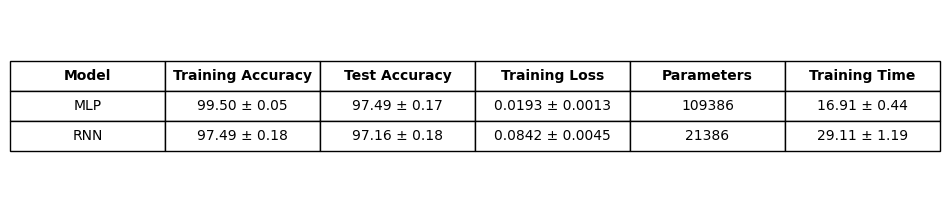

In [64]:
# Save the comparison table as a PNG image
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.axis('off')

table = ax.table(
    cellText=comparison_table.values,
    colLabels=comparison_table.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

# Make column headings bold
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold')

plt.savefig(
    'MLP_RNN_Comparison_Table.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

The MLP achieved a slightly higher average test accuracy of 97.49%, compared with 97.16% for the RNN. The MLP also trained faster, while the RNN used fewer trainable parameters. Both models showed relatively small variations in test accuracy across the five random seeds.

#### 4.2 Training Accuracy Comparison

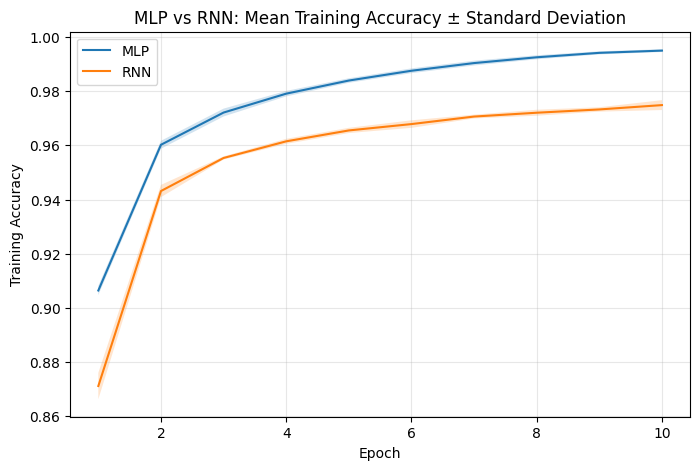

In [62]:
import numpy as np
import matplotlib.pyplot as plt

def plot_comparison(metric, ylabel, title):
    plt.figure(figsize=(8, 5))

    for histories, name in [
        (MLP_History, 'MLP'),
        (RNN_History, 'RNN')
    ]:
        values = np.array([h[metric] for h in histories])

        mean = values.mean(axis=0)
        std = values.std(axis=0, ddof=1)
        epochs = np.arange(1, len(mean) + 1)

        plt.plot(epochs, mean, label=name)
        plt.fill_between(epochs, mean - std, mean + std, alpha=0.2)

    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_comparison(
    'accuracy',
    'Training Accuracy',
    'MLP vs RNN: Mean Training Accuracy ± Standard Deviation'
)

#### 4.3 Training Loss Comparison

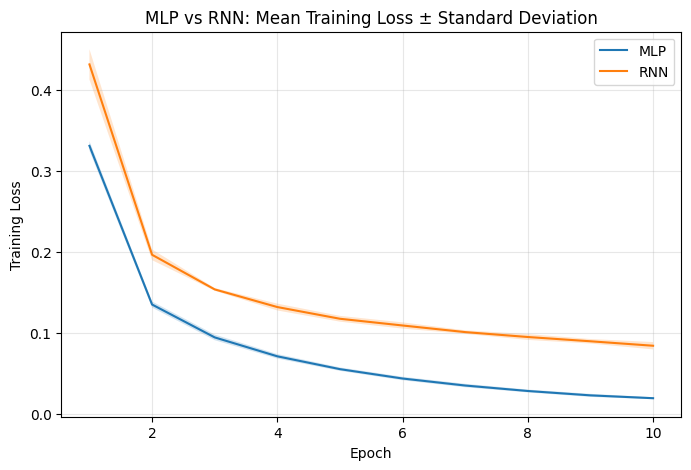

In [63]:
plot_comparison(
    'loss',
    'Training Loss',
    'MLP vs RNN: Mean Training Loss ± Standard Deviation'
)